In [27]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

In [28]:
df = pd.read_csv(r"archive\Training.csv")

In [29]:
test_df = pd.read_csv(r"archive\Testing.csv")

In [30]:
df.head()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,Unnamed: 133
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,NaN


In [31]:
df.tail()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,Unnamed: 133
4915,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,(vertigo) Paroymsal Positional Vertigo,NaN
4916,0,1,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,Acne,NaN
4917,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Urinary tract infection,NaN
4918,0,1,0,0,0,0,1,0,0,0,...,0,1,1,1,1,0,0,0,Psoriasis,NaN
4919,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,1,1,Impetigo,NaN


In [32]:
df.shape , test_df.shape

((4920, 134), (42, 133))

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4920 entries, 0 to 4919
Columns: 134 entries, itching to Unnamed: 133
dtypes: float64(1), int64(132), object(1)
memory usage: 5.0+ MB


In [34]:
df.columns

Index(['itching', 'skin_rash', 'nodal_skin_eruptions', 'continuous_sneezing',
       'shivering', 'chills', 'joint_pain', 'stomach_pain', 'acidity',
       'ulcers_on_tongue',
       ...
       'scurring', 'skin_peeling', 'silver_like_dusting',
       'small_dents_in_nails', 'inflammatory_nails', 'blister',
       'red_sore_around_nose', 'yellow_crust_ooze', 'prognosis',
       'Unnamed: 133'],
      dtype='object', length=134)

### **Data Cleaning**

In [35]:
df.isnull().sum().sum()

np.int64(4920)

In [36]:
df.isnull().sum()[df.isnull().sum() > 0]

Unnamed: 133    4920
dtype: int64

In [37]:
df.drop(columns= 'Unnamed: 133' , inplace= True)
df.shape

(4920, 133)

In [38]:
[col for col in df.columns if ' ' in col]

['spotting_ urination', 'foul_smell_of urine', 'dischromic _patches']

In [39]:
df.columns = df.columns.str.replace(r'_?\s+_?' , '_' , regex= True)
test_df.columns = test_df.columns.str.replace(r'_?\s+_?' , '_' , regex= True)

[col for col in df.columns if ' ' in col]

[]

In [40]:
list(df.columns) == list(test_df.columns)

True

In [41]:
df[df['prognosis'] != df['prognosis'].str.strip()]['prognosis'].unique()

array(['Diabetes ', 'Hypertension '], dtype=object)

In [42]:
label_fix = {'(vertigo) Paroymsal  Positional Vertigo': '(vertigo) Paroxysmal Positional Vertigo' ,
             'Peptic ulcer diseae': 'Peptic ulcer disease' ,
             'Dimorphic hemmorhoids(piles)': 'Dimorphic hemorrhoids (piles)' ,
             'Osteoarthristis': 'Osteoarthritis' ,
             'hepatitis A': 'Hepatitis A'}

for data in [df , test_df]:
    data['prognosis'] = data['prognosis'].str.strip().replace(label_fix)

In [43]:
set(df['prognosis']) == set(test_df['prognosis'])

True

In [44]:
df['prognosis'].nunique()

41

In [45]:
symptom_cols = df.columns.drop('prognosis')
df[symptom_cols].isin([0 , 1]).all().all()

np.True_

In [46]:
const_cols = [col for col in symptom_cols if df[col].nunique() == 1]
const_cols

['fluid_overload']

In [47]:
df.drop(columns= const_cols , inplace= True)
test_df.drop(columns= const_cols , inplace= True)
df.shape , test_df.shape

((4920, 132), (42, 132))

In [48]:
df.duplicated().sum()

np.int64(4616)

In [49]:
df.duplicated().mean() * 100

np.float64(93.82113821138212)

In [50]:
df.drop_duplicates(inplace= True)
df.duplicated().sum()

np.int64(0)

In [51]:
df.reset_index(drop= True , inplace= True)
df.shape

(304, 132)

In [52]:
df['prognosis'].value_counts()

prognosis
Migraine                                   10
Dengue                                     10
Hepatitis D                                10
Chicken pox                                10
Typhoid                                     9
Hepatitis B                                 9
Jaundice                                    9
Hepatitis A                                 9
Diabetes                                    9
Hepatitis E                                 9
Pneumonia                                   9
Common Cold                                 9
Hypoglycemia                                9
Hyperthyroidism                             9
Tuberculosis                                9
Alcoholic hepatitis                         8
Chronic cholestasis                         8
Varicose veins                              8
Hypothyroidism                              8
Malaria                                     8
(vertigo) Paroxysmal Positional Vertigo     7
Bronchial Asthma        

### **Data Transformation**

In [53]:
symptom_cols = df.columns.drop('prognosis')
len(symptom_cols)

131

In [54]:
df['symptom_count'] = df[symptom_cols].sum(axis= 1)

In [55]:
symptom_freq = df[symptom_cols].sum().sort_values(ascending= False)
symptom_freq.head(10)

fatigue              134
vomiting             117
high_fever            89
loss_of_appetite      81
nausea                77
headache              74
abdominal_pain        70
yellowish_skin        61
yellowing_of_eyes     58
chills                53
dtype: int64

In [56]:
disease_symptoms = df.groupby('prognosis')[symptom_cols].max()
disease_symptoms.shape

(41, 131)

In [57]:
symptoms_per_disease = disease_symptoms.sum(axis= 1).sort_values()
symptoms_per_disease.head()

prognosis
AIDS                4
Acne                4
Allergy             4
Fungal infection    4
Heart attack        4
dtype: int64

In [58]:
diseases_per_symptom = disease_symptoms.sum().sort_values(ascending= False)
diseases_per_symptom.head()

fatigue             17
vomiting            17
high_fever          12
headache            10
loss_of_appetite    10
dtype: int64

In [59]:
df.head()

,itching,skin_rash,nodal_skin_eruptions,continuous_sneezing,shivering,chills,joint_pain,stomach_pain,acidity,ulcers_on_tongue,...,scurring,skin_peeling,silver_like_dusting,small_dents_in_nails,inflammatory_nails,blister,red_sore_around_nose,yellow_crust_ooze,prognosis,symptom_count
0,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,4
1,0,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,3
2,1,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,3
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,3
4,1,1,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,Fungal infection,3


### **EDA && Visualization**

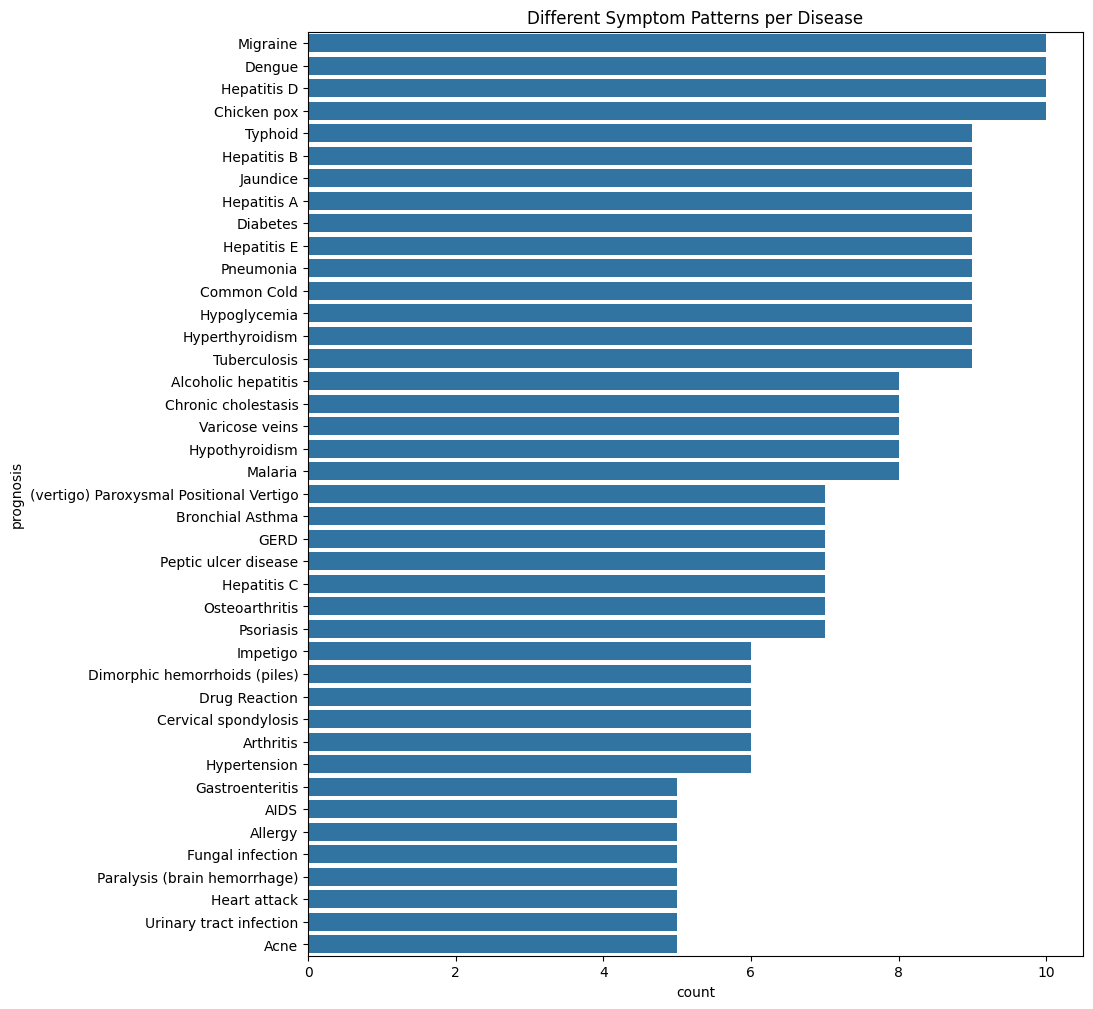

In [60]:
plt.figure(figsize= (10,12))
plt.title('Different Symptom Patterns per Disease')
sns.countplot(data= df , y= 'prognosis' , order= df['prognosis'].value_counts().index)
plt.show()

In [61]:
df['symptom_count'].describe()

count    304.000000
mean       7.648026
std        3.602043
min        3.000000
25%        5.000000
50%        7.000000
75%       10.000000
max       17.000000
Name: symptom_count, dtype: float64

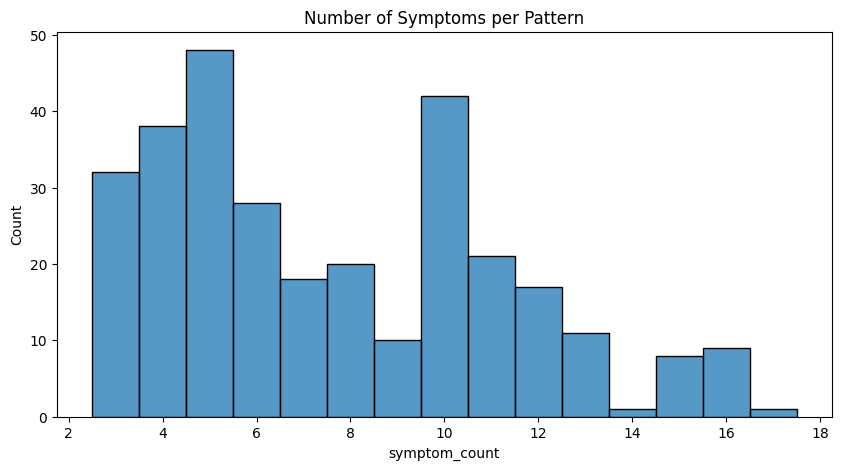

In [62]:
plt.figure(figsize= (10,5))
plt.title('Number of Symptoms per Pattern')
sns.histplot(data= df , x= 'symptom_count' , discrete= True)
plt.show()

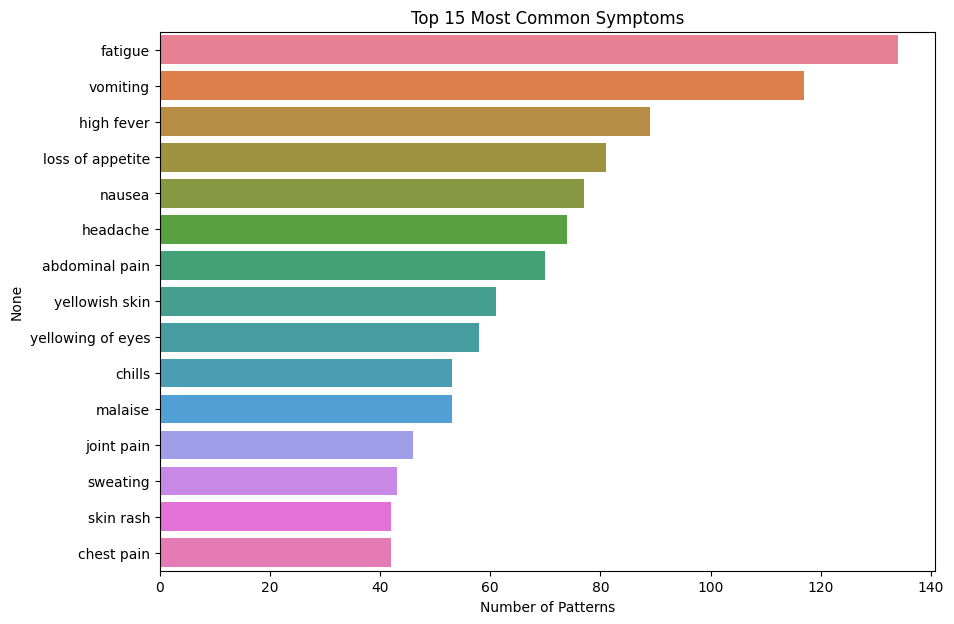

In [63]:
top_symptoms = symptom_freq.head(15)
top_symptoms.index = top_symptoms.index.str.replace('_' , ' ')

plt.figure(figsize= (10,7))
plt.title('Top 15 Most Common Symptoms')
sns.barplot( x = top_symptoms.values , y= top_symptoms.index , hue= top_symptoms.index)
plt.xlabel('Number of Patterns')
plt.show()

In [64]:
symptom_freq.tail(10)

weakness_of_one_body_side    4
continuous_feel_of_urine     4
altered_sensorium            4
bladder_discomfort           4
foul_smell_of_urine          4
dischromic_patches           4
watering_from_eyes           4
pus_filled_pimples           4
blackheads                   4
scurring                     4
dtype: int64

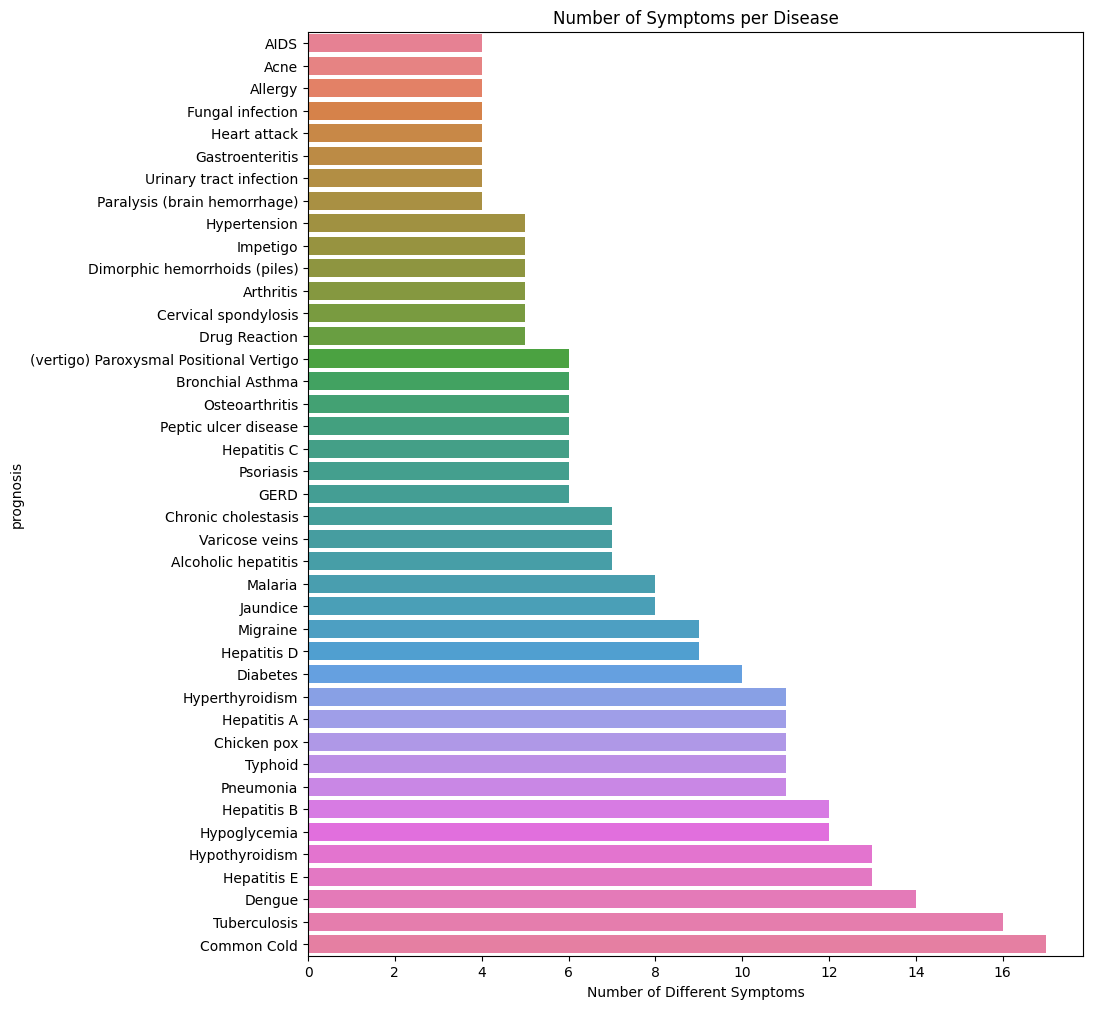

In [65]:
plt.figure(figsize= (10,12))
plt.title('Number of Symptoms per Disease')
sns.barplot( x = symptoms_per_disease.values , y= symptoms_per_disease.index , hue= symptoms_per_disease.index)
plt.xlabel('Number of Different Symptoms')
plt.show()

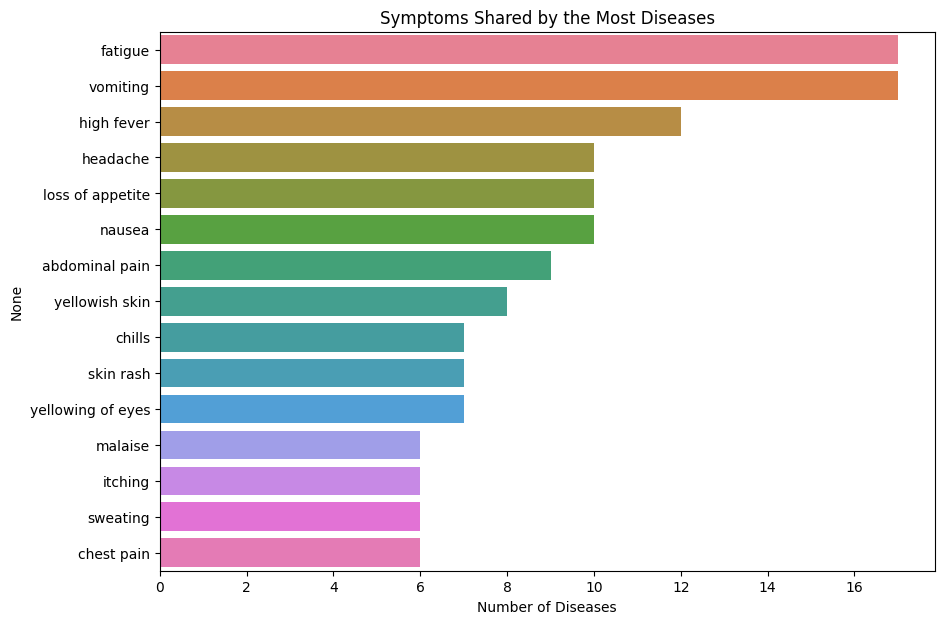

In [66]:
shared_symptoms = diseases_per_symptom.head(15)
shared_symptoms.index = shared_symptoms.index.str.replace('_' , ' ')

plt.figure(figsize= (10,7))
plt.title('Symptoms Shared by the Most Diseases')
sns.barplot( x = shared_symptoms.values , y= shared_symptoms.index , hue= shared_symptoms.index)
plt.xlabel('Number of Diseases')
plt.show()

In [67]:
diseases_per_symptom.value_counts().sort_index()

1     80
2     20
3      6
4      6
5      3
6      5
7      3
8      1
9      1
10     3
12     1
17     2
Name: count, dtype: int64

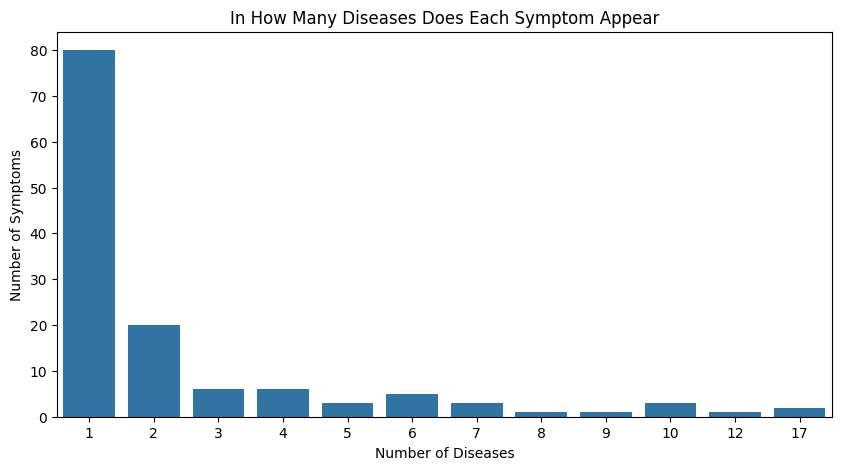

In [68]:
plt.figure(figsize= (10,5))
plt.title('In How Many Diseases Does Each Symptom Appear')
sns.countplot(x= diseases_per_symptom.values)
plt.xlabel('Number of Diseases')
plt.ylabel('Number of Symptoms')
plt.show()

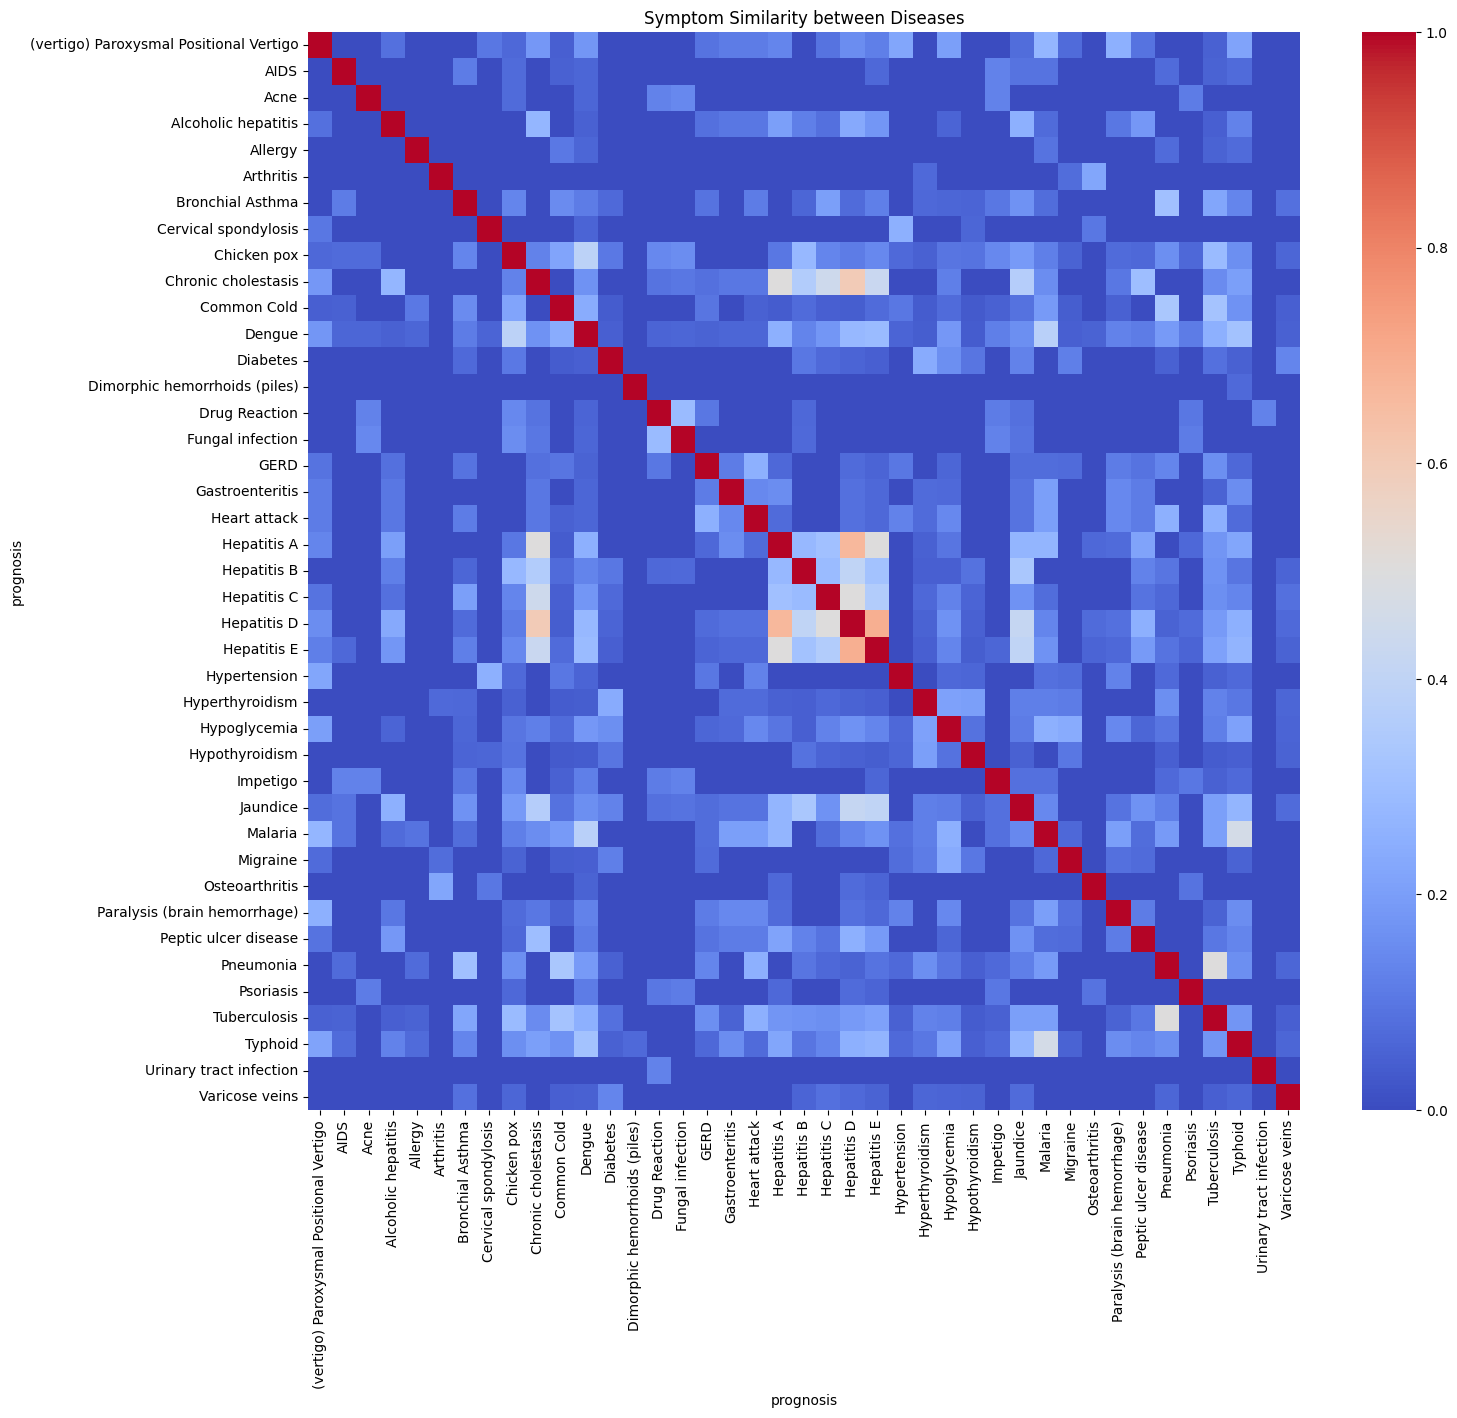

In [69]:
shared = disease_symptoms.dot(disease_symptoms.T)
sizes = disease_symptoms.sum(axis= 1).values
similarity = shared / (sizes[: , None] + sizes[None , :] - shared)

plt.figure(figsize= (16,14))
plt.title('Symptom Similarity between Diseases')
sns.heatmap(similarity , cmap= 'coolwarm')
plt.show()

In [70]:
pairs = similarity.where(np.triu(np.ones(similarity.shape) , k= 1).astype(bool)).stack().sort_values(ascending= False)
pairs.head(10)

prognosis            prognosis   
Hepatitis D          Hepatitis E     0.692308
Hepatitis A          Hepatitis D     0.666667
Chronic cholestasis  Hepatitis D     0.600000
Hepatitis A          Hepatitis E     0.500000
Chronic cholestasis  Hepatitis A     0.500000
Pneumonia            Tuberculosis    0.500000
Hepatitis C          Hepatitis D     0.500000
Malaria              Typhoid         0.461538
Chronic cholestasis  Hepatitis C     0.444444
                     Hepatitis E     0.428571
dtype: float64